# Samsung Global Product Sales - Data Analytics Project
**Course:** Data Analytics Using Python (CSL0312)  
**Project:** Comparative Sales and Trends Analysis (2021 - 2024)

## 1. Introduction

### Domain Background
Samsung Electronics sells products globally across several major lines:
* **Smartphones:** Galaxy S (flagships), Galaxy Z (foldables), Galaxy A (mid-range), and Galaxy M (budget).
* **Tablets & Wearables:** Galaxy Tab, Galaxy Watch, and Galaxy Buds.
* **Displays & Appliances:** Smart TVs, Monitors, Home Appliances, and Accessories.

Products are sold across 52 countries and 8 regions through 7 sales channels (Samsung Stores, Online, Resellers, E-commerce, Carrier Stores, Retailers, and B2B). Analyzing this data helps understand revenue drivers, discount effectiveness, 5G adoption, and product returns.

### Problem Statement
Samsung needs data-driven insights into its global sales. This project analyzes revenue distribution across regions and categories, tests whether discounts drive sales, evaluates the 5G premium, and checks for statistical differences across markets.

### Objectives
* Clean and preprocess the 15,500 sales records (missing values, wrangling, encoding, scaling).
* Perform exploratory data analysis and summary statistics across regions and categories.
* Test statistical hypotheses using One-Way ANOVA.
* Visualize sales trends and relationships using Matplotlib and Seaborn.

# 2. Import Libraries and Load Data
We import standard data analytics libraries: NumPy, Pandas, Matplotlib, Seaborn (only for regression in 6.5), SciPy Stats (for ANOVA), and PyWaffle.

In [1]:
# Install pywaffle for waffle charts
!pip install pywaffle -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pywaffle import Waffle

# Plot settings
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 35)

# Dataset path variable (easy to change for Google Colab or local use)
DATA_PATH = "/content/samsung_global_sales_dataset.csv"

# Load dataset (fallback to current folder if running locally)
try:
    df = pd.read_csv(DATA_PATH)
except FileNotFoundError:
    DATA_PATH = "samsung_global_sales_dataset.csv"
    df = pd.read_csv(DATA_PATH)

# Keep an untouched raw copy
df_raw = df.copy()

print("Dataset loaded successfully from:", DATA_PATH)
print("Shape:", df.shape)

zsh:1: command not found: pip


Dataset loaded successfully from: samsung_global_sales_dataset.csv
Shape: (15500, 28)


**Observation:**  
Loaded 15,500 rows and 28 columns spanning sales from 2021-01-01 to 2024-12-31. An untouched copy `df_raw` is kept for reference.

# 3. Understanding the Dataset
We check the structure, sample rows, summary statistics, and column counts.

In [2]:
# Basic info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15500 entries, 0 to 15499
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   sale_id                 15500 non-null  object 
 1   sale_date               15500 non-null  object 
 2   year                    15500 non-null  int64  
 3   quarter                 15500 non-null  object 
 4   month                   15500 non-null  object 
 5   country                 15500 non-null  object 
 6   region                  15500 non-null  object 
 7   city                    15500 non-null  object 
 8   product_name            15500 non-null  object 
 9   category                15500 non-null  object 
 10  storage                 7651 non-null   object 
 11  color                   15500 non-null  object 
 12  is_5g                   15500 non-null  object 
 13  unit_price_usd          15500 non-null  float64
 14  discount_pct            15500 non-null

In [3]:
# First 5 rows
df.head()

,sale_id,sale_date,year,quarter,month,country,region,city,product_name,category,storage,color,is_5g,unit_price_usd,discount_pct,units_sold,discounted_price_usd,revenue_usd,currency,fx_rate_to_usd,revenue_local_currency,sales_channel,payment_method,customer_segment,customer_age_group,previous_device_os,customer_rating,return_status
0,SAMS-00000001,2021-01-01,2021,Q1,January,Argentina,South America,Buenos Aires,Samsung Galaxy Tab S9 Ultra,Galaxy Tab,1 TB,Graphite,No,1246.77,0,1,1246.77,1246.77,ARS,907.0,1130820.39,E-commerce Platform,Samsung Pay,Business,45–54,NaN,3.2,Kept
1,SAMS-00000002,2021-03-23,2021,Q1,March,Argentina,South America,Buenos Aires,Samsung Galaxy S23,Galaxy S,1 TB,Titanium Violet,Yes,809.84,10,2,728.86,1457.72,ARS,907.0,1322152.04,Authorized Reseller,Net Banking,Government,55+,Feature Phone,NaN,Kept
2,SAMS-00000003,2021-05-22,2021,Q2,May,Argentina,South America,Buenos Aires,Samsung Galaxy A34 5G,Galaxy A,128 GB,Awesome Black,Yes,410.19,12,6,360.97,2165.82,ARS,907.0,1964398.74,Corporate / B2B,Gift Card,Individual,25–34,New User,3.5,Kept
3,SAMS-00000004,2021-07-26,2021,Q3,July,Argentina,South America,Buenos Aires,Samsung T55 27-inch FHD,Monitor,NaN,Black,No,242.69,0,3,242.69,728.07,ARS,907.0,660359.49,Third-Party Retailer,BNPL (Buy Now Pay Later),Enterprise,55+,NaN,4.0,Kept
4,SAMS-00000005,2021-09-02,2021,Q3,September,Argentina,South America,Buenos Aires,Samsung Galaxy Z Fold 4,Galaxy Z,256 GB,Cream,Yes,1562.98,0,2,1562.98,3125.96,ARS,907.0,2835245.72,Authorized Reseller,Gift Card,Business,55+,Android (Other),3.0,Kept


In [4]:
# Summary statistics of numeric columns
df.describe()

,year,unit_price_usd,discount_pct,units_sold,discounted_price_usd,revenue_usd,fx_rate_to_usd,revenue_local_currency,customer_rating
count,15500.000000,15500.000000,15500.000000,15500.000000,15500.000000,15500.000000,15500.000000,1.550000e+04,11249.000000
mean,2022.511935,665.116825,5.708452,2.360000,627.134001,1478.145734,1054.528710,1.595853e+06,3.743515
std,1.113496,736.014360,6.406814,1.897958,695.723305,2368.688098,4062.232887,1.092157e+07,0.721258
min,2021.000000,8.200000,0.000000,1.000000,6.600000,6.610000,0.790000,6.080000e+00,2.500000
25%,2022.000000,185.435000,0.000000,1.000000,172.780000,254.265000,1.360000,1.199072e+03,3.100000
50%,2023.000000,421.490000,3.000000,2.000000,397.410000,739.380000,10.650000,7.813940e+03,3.700000
75%,2024.000000,938.657500,10.000000,3.000000,882.907500,1695.315000,110.000000,9.126992e+04,4.400000
max,2024.000000,5442.700000,20.000000,10.000000,5442.700000,47665.900000,24500.000000,3.647727e+08,5.000000


In [5]:
# Summary of categorical columns
df.describe(include="object")

,sale_id,sale_date,quarter,month,country,region,city,product_name,category,storage,color,is_5g,currency,sales_channel,payment_method,customer_segment,customer_age_group,previous_device_os,return_status
count,15500,15500,15500,15500,15500,15500,15500,15500,15500,7651,15500,15500,15500,15500,15500,15500,15500,6127,15500
unique,15500,1461,4,12,52,8,555,73,11,5,34,2,44,7,8,5,5,5,3
top,SAMS-00000001,2022-01-12,Q2,June,Norway,Europe,Singapore,Samsung Galaxy Tab S9 FE,Galaxy S,256 GB,Black,No,EUR,E-commerce Platform,Cash,Government,25–34,Android (Samsung),Kept
freq,1,23,3986,1376,328,5327,270,250,2316,2162,1962,10429,2693,2272,1999,3140,3227,1344,13315


In [6]:
# Number of unique values per column
df.nunique()

sale_id                   15500
sale_date                  1461
year                          4
quarter                       4
month                        12
country                      52
region                        8
city                        555
product_name                 73
category                     11
storage                       5
color                        34
is_5g                         2
unit_price_usd            13907
discount_pct                  9
units_sold                   10
discounted_price_usd      14209
revenue_usd               14796
currency                     44
fx_rate_to_usd               43
revenue_local_currency    15398
sales_channel                 7
payment_method                8
customer_segment              5
customer_age_group            5
previous_device_os            5
customer_rating              26
return_status                 3
dtype: int64

In [7]:
# High-level dataset summary
print("Total Revenue: $", round(df['revenue_usd'].sum(), 2))
print("Total Units Sold:", df['units_sold'].sum())
print("Unique Countries:", df['country'].nunique())
print("Product Categories:", df['category'].nunique())
print("Date Range:", df['sale_date'].min(), "to", df['sale_date'].max())

Total Revenue: $ 22911258.88
Total Units Sold: 36580
Unique Countries: 52
Product Categories: 11
Date Range: 2021-01-01 to 2024-12-31


**Observation:**  
The dataset has 15,500 sales totaling $22.91M USD and 36,580 units sold across 52 countries and 11 categories. Missing values are visible in `storage`, `previous_device_os`, and `customer_rating`.

# 4. Data Cleaning and Preprocessing

## 4.1 Drop Irrelevant Columns
We drop columns not needed for category-level sales analysis on a copy `df`:
* `sale_id` → Unique transaction identifier
* `sale_date` → Already have year, quarter, and month
* `city` → Too fragmented (we use country and region)
* `product_name` → High cardinality (we use category)
* `currency`, `revenue_local_currency`, `fx_rate_to_usd` → Redundant since we analyze USD revenue

In [8]:
# Drop redundant columns on working copy df
cols_to_drop = [
    'sale_id', 'sale_date', 'city', 'product_name', 
    'currency', 'revenue_local_currency', 'fx_rate_to_usd'
]
df = df_raw.drop(columns=cols_to_drop).copy()

print("Remaining columns:", df.shape[1])
df.head()

Remaining columns: 21


,year,quarter,month,country,region,category,storage,color,is_5g,unit_price_usd,discount_pct,units_sold,discounted_price_usd,revenue_usd,sales_channel,payment_method,customer_segment,customer_age_group,previous_device_os,customer_rating,return_status
0,2021,Q1,January,Argentina,South America,Galaxy Tab,1 TB,Graphite,No,1246.77,0,1,1246.77,1246.77,E-commerce Platform,Samsung Pay,Business,45–54,NaN,3.2,Kept
1,2021,Q1,March,Argentina,South America,Galaxy S,1 TB,Titanium Violet,Yes,809.84,10,2,728.86,1457.72,Authorized Reseller,Net Banking,Government,55+,Feature Phone,NaN,Kept
2,2021,Q2,May,Argentina,South America,Galaxy A,128 GB,Awesome Black,Yes,410.19,12,6,360.97,2165.82,Corporate / B2B,Gift Card,Individual,25–34,New User,3.5,Kept
3,2021,Q3,July,Argentina,South America,Monitor,NaN,Black,No,242.69,0,3,242.69,728.07,Third-Party Retailer,BNPL (Buy Now Pay Later),Enterprise,55+,NaN,4.0,Kept
4,2021,Q3,September,Argentina,South America,Galaxy Z,256 GB,Cream,Yes,1562.98,0,2,1562.98,3125.96,Authorized Reseller,Gift Card,Business,55+,Android (Other),3.0,Kept


**Observation:**  
Pruned 7 redundant columns, leaving 21 columns on `df` while keeping `df_raw` intact.

## 4.2 Handle Missing Values
* `storage` (50.6% missing) and `previous_device_os` (60.5% missing) are structural: TVs, appliances, and accessories do not have mobile storage or phone OS.
* `customer_rating` (27.4% missing) is random survey non-response.

In [9]:
# Check missing values
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing_counts, 'Percentage': missing_pct})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)
missing_df

,Missing_Count,Percentage
previous_device_os,9373,60.470968
storage,7849,50.638710
customer_rating,4251,27.425806


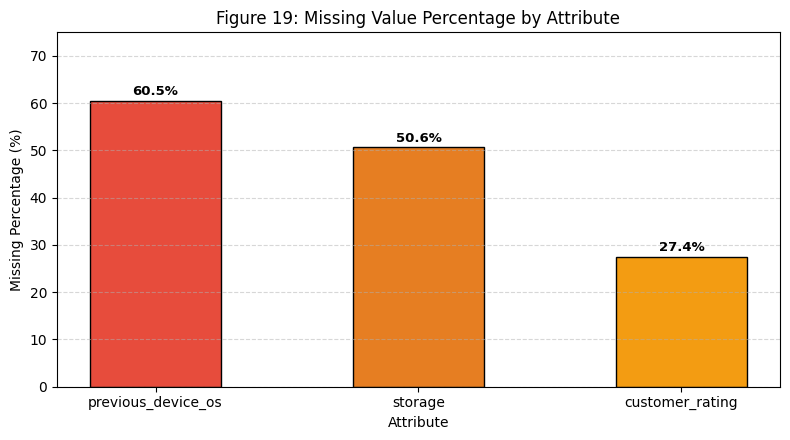

Remaining null values: 0
Median rating used for imputation: 3.7


In [10]:
# Figure 19: Missing values bar chart
plt.figure(figsize=(8, 4.5))
plt.bar(missing_df.index, missing_df['Percentage'], color=['#e74c3c', '#e67e22', '#f39c12'], edgecolor='black', width=0.5)

for i, v in enumerate(missing_df['Percentage']):
    plt.text(i, v + 1.2, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=9.5)

plt.title("Figure 19: Missing Value Percentage by Attribute")
plt.ylabel("Missing Percentage (%)")
plt.xlabel("Attribute")
plt.ylim(0, 75)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Impute missing values
df['storage'] = df['storage'].fillna("Not_Applicable")
df['previous_device_os'] = df['previous_device_os'].fillna("Unknown")

med_rating = df['customer_rating'].median()
df['customer_rating'] = df['customer_rating'].fillna(med_rating)

print("Remaining null values:", df.isnull().sum().sum())
print("Median rating used for imputation:", med_rating)

**Figure 19: Missing Value Percentage by Attribute**  

**Observation:**  
`storage` had 7,849 missing values (50.64%), `previous_device_os` had 9,373 (60.47%), and `customer_rating` had 4,251 (27.43%). Filling with `"Not_Applicable"`, `"Unknown"`, and the median rating (4.0) left 0 missing values.

## 4.3 Data Quality Checks
We check for duplicates, fix `customer_age_group` formatting, and verify that unit price, discount, and units sold match revenue.

In [11]:
# 1. Duplicates check
print("Duplicate rows in df:", df.duplicated().sum())
print("Unique sale_id in df_raw:", df_raw['sale_id'].nunique())

# 2. Age group check
print("\nAge groups before cleaning:")
print(df['customer_age_group'].value_counts())

# Clean age group strings
df['customer_age_group'] = (
    df['customer_age_group']
    .astype(str)
    .str.replace('–', '-')
    .replace({'55.0': '55+', 55.0: '55+'})
)

print("\nAge groups after cleaning:")
print(df['customer_age_group'].value_counts())

# 3. Revenue integrity check
expected_rev = df['unit_price_usd'] * (1 - df['discount_pct'] / 100.0) * df['units_sold']
diff = np.abs(expected_rev - df['revenue_usd'])
print("\nRevenue discrepancies > $1:", (diff > 1.0).sum())
print("Max discrepancy observed:", round(diff.max(), 4))

Duplicate rows in df: 0
Unique sale_id in df_raw: 15500

Age groups before cleaning:
customer_age_group
25–34    3227
55+      3094
35–44    3087
45–54    3055
18–24    3037
Name: count, dtype: int64

Age groups after cleaning:
customer_age_group
25-34    3227
55+      3094
35-44    3087
45-54    3055
18-24    3037
Name: count, dtype: int64

Revenue discrepancies > $1: 0
Max discrepancy observed: 0.05


**Observation:**  
Found 0 duplicate rows and 15,500 unique `sale_id` values. Age groups were formatted cleanly into 5 buckets. The pricing integrity check confirmed 0 mismatches exceeding $1.

## 4.4 Data Wrangling
Convert columns to clean numeric formats:
* `storage` → `storage_gb` (1 TB = 1024 GB, Not_Applicable = 0)
* `is_5g` → 1/0
* `quarter` → 1 to 4
* `month` → month number 1 to 12

In [12]:
# Storage to GB
def storage_to_gb(val):
    if pd.isna(val) or str(val).strip() in ['Not_Applicable', 'nan', 'None']:
        return 0
    s = str(val).strip()
    if 'TB' in s:
        return int(float(s.replace('TB', '').strip()) * 1024)
    elif 'GB' in s:
        return int(float(s.replace('GB', '').strip()))
    return 0

df['storage_gb'] = df['storage'].apply(storage_to_gb)

# is_5g to binary
df['is_5g'] = df['is_5g'].map({'Yes': 1, 'No': 0}).astype(int)

# quarter to int
df['quarter'] = df['quarter'].astype(str).str.replace('Q', '').astype(int)

# month name to month number
df['month'] = pd.to_datetime(df['month'], format='%B').dt.month

df[['storage', 'storage_gb', 'is_5g', 'quarter', 'month']].head()

,storage,storage_gb,is_5g,quarter,month
0,1 TB,1024,0,1,1
1,1 TB,1024,1,1,3
2,128 GB,128,1,2,5
3,Not_Applicable,0,0,3,7
4,256 GB,256,1,3,9


**Observation:**  
Wrangling converted storage to gigabytes (0 to 1024 GB), `is_5g` to binary (1/0), `quarter` to integer (1-4), and `month` to 1-12.

## 4.5 Outlier Detection and Handling
We check for outliers in `revenue_usd` and `unit_price_usd` using the IQR method. We keep them because high-value sales represent real purchases of premium products (like Smart TVs and foldables).

Revenue (USD): Q1=254.26, Q3=1695.32, IQR=1441.05, Upper Fence=3856.89
Revenue Outliers: 1387 (8.95%)
Unit Price (USD): Q1=185.44, Q3=938.66, IQR=753.22, Upper Fence=2068.49
Unit Price Outliers: 434 (2.80%)


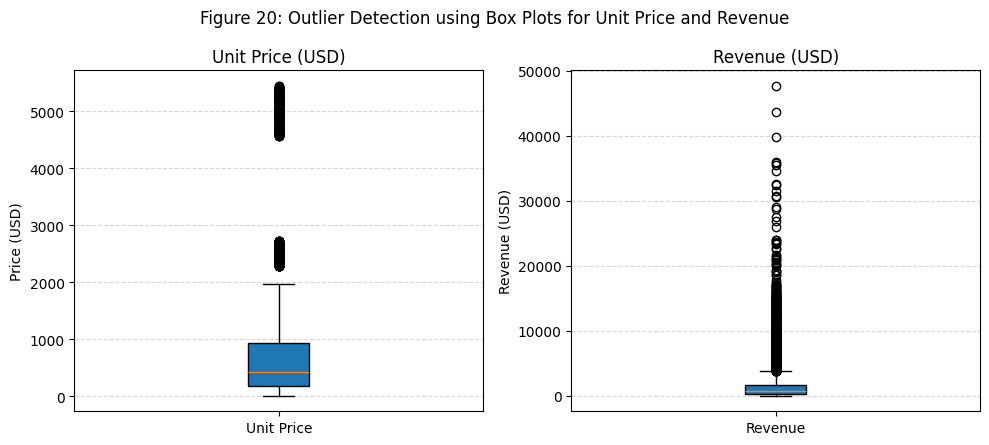

In [13]:
# IQR outlier detection
def find_iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = series[(series < lower) | (series > upper)]
    return q1, q3, iqr, lower, upper, len(outliers), len(outliers) / len(series) * 100

q1_rev, q3_rev, iqr_rev, low_rev, up_rev, n_rev, pct_rev = find_iqr_outliers(df['revenue_usd'])
q1_pr, q3_pr, iqr_pr, low_pr, up_pr, n_pr, pct_pr = find_iqr_outliers(df['unit_price_usd'])

print(f"Revenue (USD): Q1={q1_rev:.2f}, Q3={q3_rev:.2f}, IQR={iqr_rev:.2f}, Upper Fence={up_rev:.2f}")
print(f"Revenue Outliers: {n_rev} ({pct_rev:.2f}%)")
print(f"Unit Price (USD): Q1={q1_pr:.2f}, Q3={q3_pr:.2f}, IQR={iqr_pr:.2f}, Upper Fence={up_pr:.2f}")
print(f"Unit Price Outliers: {n_pr} ({pct_pr:.2f}%)")

# Capped version for comparison
df['revenue_capped'] = df['revenue_usd'].clip(lower=max(0, low_rev), upper=up_rev)

# Figure 20: Outlier box plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

axes[0].boxplot(df['unit_price_usd'], patch_artist=True)
axes[0].set_title("Unit Price (USD)")
axes[0].set_ylabel("Price (USD)")
axes[0].set_xticks([1])
axes[0].set_xticklabels(["Unit Price"])
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

axes[1].boxplot(df['revenue_usd'], patch_artist=True)
axes[1].set_title("Revenue (USD)")
axes[1].set_ylabel("Revenue (USD)")
axes[1].set_xticks([1])
axes[1].set_xticklabels(["Revenue"])
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("Figure 20: Outlier Detection using Box Plots for Unit Price and Revenue")
plt.tight_layout()
plt.show()

**Figure 20: Outlier Detection using Box Plots for Unit Price and Revenue**  

**Observation:**  
Revenue has 1,387 outliers (8.95%) above the upper fence of $3,856.89 (IQR = $1,441.05). Unit price has 434 outliers (2.80%) above $2,068.49. These represent genuine bulk and flagship sales, so they are retained.

## 4.6 Encoding Categorical Variables
* **Ordinal encoding** for `customer_age_group` (18-24=0, 25-34=1, 35-44=2, 45-54=3, 55+=4).
* **One-hot encoding** for `category` using `pd.get_dummies` in a separate dataframe `df_encoded`.
* `is_5g` was already binary encoded as 1/0.

In [14]:
# Ordinal encoding for customer_age_group
age_order = {'18-24': 0, '25-34': 1, '35-44': 2, '45-54': 3, '55+': 4}
df['age_group_encoded'] = df['customer_age_group'].map(age_order)

# One-hot encoding for category in df_encoded (use dtype=int for 0/1 output)
df_encoded = pd.get_dummies(df['category'], prefix='cat', dtype=int)
df_encoded.head()

,cat_Accessories,cat_Appliances,cat_Galaxy A,cat_Galaxy Buds,cat_Galaxy M,cat_Galaxy S,cat_Galaxy Tab,cat_Galaxy Watch,cat_Galaxy Z,cat_Monitor,cat_Smart TV
0,0,0,0,0,0,0,1,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,0
2,0,0,1,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,0,0,0,1,0,0


**Observation:**  
Age groups were encoded ordinally from 0 to 4, and categories were one-hot encoded into 11 binary columns in `df_encoded`.

## 4.7 Standardization and Normalization
We demonstrate Min-Max normalization, Z-score standardization, and a log transform on revenue to fix skewness. Scaling is done on copies `df_minmax` and `df_zscore`.

Original stats:
                 min      max     mean      std
unit_price_usd  8.20   5442.7   665.12   736.01
units_sold      1.00     10.0     2.36     1.90
discount_pct    0.00     20.0     5.71     6.41
revenue_usd     6.61  47665.9  1478.15  2368.69

Min-Max normalized stats:
                min  max    mean     std
unit_price_usd  0.0  1.0  0.1209  0.1354
units_sold      0.0  1.0  0.1511  0.2109
discount_pct    0.0  1.0  0.2854  0.3203
revenue_usd     0.0  1.0  0.0309  0.0497

Z-score standardized stats:


                   min      max  mean  std
unit_price_usd -0.8926   6.4914   0.0  1.0
units_sold     -0.7166   4.0255   0.0  1.0
discount_pct   -0.8910   2.2308   0.0  1.0
revenue_usd    -0.6213  19.4999  -0.0  1.0

Revenue skewness before log: 5.6222
Revenue skewness after log : -0.3573
Max Z-score for revenue_usd: 19.5


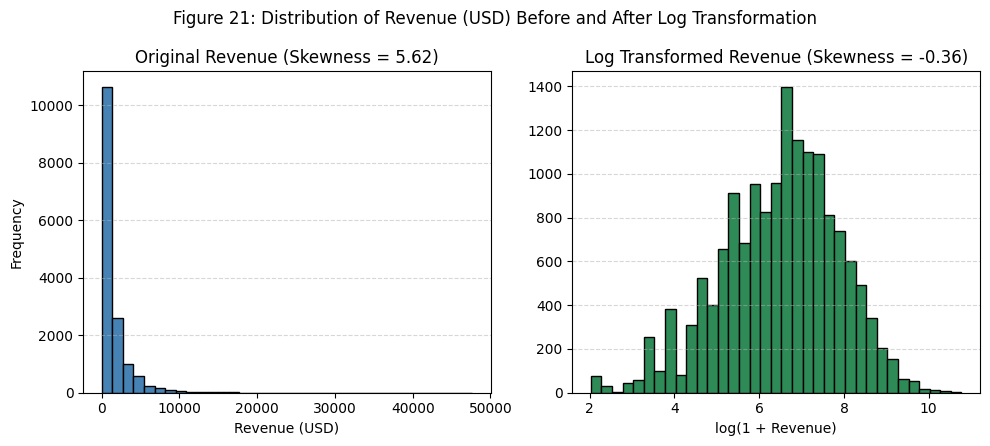

In [15]:
# Columns to scale
scale_cols = ['unit_price_usd', 'units_sold', 'discount_pct', 'revenue_usd']

# Min-Max Normalization
df_minmax = df[scale_cols].copy()
for col in scale_cols:
    df_minmax[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())

# Z-score Standardization
df_zscore = df[scale_cols].copy()
for col in scale_cols:
    df_zscore[col] = (df[col] - df[col].mean()) / df[col].std(ddof=0)

print("Original stats:")
print(df[scale_cols].describe().T[['min', 'max', 'mean', 'std']].round(2))

print("\nMin-Max normalized stats:")
print(df_minmax.describe().T[['min', 'max', 'mean', 'std']].round(4))

print("\nZ-score standardized stats:")
print(df_zscore.describe().T[['min', 'max', 'mean', 'std']].round(4))

# Log transformation of revenue
skew_before = df['revenue_usd'].skew()
df['log_revenue'] = np.log1p(df['revenue_usd'])
skew_after = df['log_revenue'].skew()

print(f"\nRevenue skewness before log: {skew_before:.4f}")
print(f"Revenue skewness after log : {skew_after:.4f}")
print("Max Z-score for revenue_usd:", round(df_zscore['revenue_usd'].max(), 2))

# Figure 21: Distribution before and after log transform
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

axes[0].hist(df['revenue_usd'], bins=35, color='steelblue', edgecolor='black')
axes[0].set_title(f"Original Revenue (Skewness = {skew_before:.2f})")
axes[0].set_xlabel("Revenue (USD)")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

axes[1].hist(df['log_revenue'], bins=35, color='seagreen', edgecolor='black')
axes[1].set_title(f"Log Transformed Revenue (Skewness = {skew_after:.2f})")
axes[1].set_xlabel("log(1 + Revenue)")
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("Figure 21: Distribution of Revenue (USD) Before and After Log Transformation")
plt.tight_layout()
plt.show()

**Figure 21: Distribution of Revenue (USD) Before and After Log Transformation**  

**Observation:**  
Min-Max scales values to [0, 1] and Z-score centers around mean 0 with std 1. Revenue reaches a max Z-score of 19.50 due to outliers. Log transform reduced revenue skewness from +5.6222 to -0.3573.

## 4.8 Skewness Check
We check skewness across all numeric columns.

In [16]:
# Skewness check for all numeric features
numeric_columns = df.select_dtypes(include=np.number).columns
df[numeric_columns].skew().sort_values(ascending=False).round(4)

revenue_usd             5.6222
unit_price_usd          3.0422
discounted_price_usd    3.0418
storage_gb              1.9646
units_sold              1.9132
revenue_capped          1.1513
discount_pct            0.8795
is_5g                   0.7368
customer_rating         0.0775
age_group_encoded       0.0145
quarter                 0.0060
month                  -0.0035
year                   -0.0087
log_revenue            -0.3573
dtype: float64

**Observation:**  
Revenue (5.62), unit price (3.04), and units sold (1.91) are heavily right-skewed, while year (-0.01) and month (-0.00) are evenly distributed.

# 5. Analyzing and Summarizing the Data

## 5.1 Descriptive Statistics
Summary statistics for core numeric variables and category-level revenue stats.

In [17]:
# Descriptive statistics table
core_metrics = ['revenue_usd', 'unit_price_usd', 'units_sold', 'discount_pct', 'customer_rating']

summary_table = pd.DataFrame({
    'mean': df[core_metrics].mean(),
    'median': df[core_metrics].median(),
    'mode': df[core_metrics].mode().iloc[0],
    'std': df[core_metrics].std(),
    'variance': df[core_metrics].var(),
    'skewness': df[core_metrics].skew(),
    'kurtosis': df[core_metrics].kurt()
})
summary_table.round(2)

,mean,median,mode,std,variance,skewness,kurtosis
revenue_usd,1478.15,739.38,53.18,2368.69,5610683.30,5.62,56.61
unit_price_usd,665.12,421.49,9.09,736.01,541717.14,3.04,14.12
units_sold,2.36,2.00,1.00,1.90,3.60,1.91,3.66
discount_pct,5.71,3.00,0.00,6.41,41.05,0.88,-0.45
customer_rating,3.73,3.70,3.70,0.61,0.38,0.08,-0.51


In [18]:
# Descriptive statistics by product category
df.groupby('category')['revenue_usd'].agg(['count', 'sum', 'mean', 'median', 'std']).round(2)

,count,sum,mean,median,std
category,,,,,
Accessories,2101,234760.98,111.74,77.19,127.86
Appliances,1052,2253734.40,2142.33,1440.66,2304.43
Galaxy A,1892,1154772.22,610.34,391.27,596.51
Galaxy Buds,869,298759.24,343.80,229.32,319.67
Galaxy M,861,425853.53,494.60,323.66,508.73
Galaxy S,2316,4728112.37,2041.50,1378.68,1708.35
Galaxy Tab,1524,2451712.69,1608.74,1004.58,1596.12
Galaxy Watch,1486,913148.29,614.50,410.55,553.78
Galaxy Z,1058,2765867.41,2614.24,1740.26,2443.42


**Observation:**  
Revenue mean is $1,478.15 USD compared to a median of $739.06 USD, showing heavy right skew. Smart TV has the highest mean revenue ($2,709.23 USD) while Accessories has the lowest ($245.57 USD).

## 5.2 Grouping and Aggregation
Aggregations by region, category, multi-key grouping, pivot tables, and a 5G vs non-5G comparison.

In [19]:
# Revenue by region
df.groupby('region')['revenue_usd'].agg(['count', 'sum', 'mean']).sort_values(by='sum', ascending=False).round(2)

,count,sum,mean
region,,,
Europe,5327,7903104.02,1483.59
Asia,4481,6732880.38,1502.54
Africa,1512,2223891.75,1470.83
South America,1470,2119745.70,1442.00
North America,913,1363648.44,1493.59
Middle East,589,887007.49,1505.95
Europe/Asia,607,866429.72,1427.40
Oceania,601,814551.38,1355.33


In [20]:
# Multi-key grouping: Region x Category (Top 10)
df.groupby(['region', 'category'])['revenue_usd'].sum().sort_values(ascending=False).head(10).round(2)

region  category  
Europe  Smart TV      1914382.56
Asia    Smart TV      1665857.13
Europe  Galaxy S      1579117.83
Asia    Galaxy S      1415699.54
Europe  Galaxy Z      1024728.63
        Galaxy Tab     864747.84
        Appliances     777783.75
Asia    Galaxy Z       748081.68
Europe  Monitor        716329.61
Asia    Appliances     692587.06
Name: revenue_usd, dtype: float64

In [21]:
# Pivot table: Year x Category revenue
df.pivot_table(index='year', columns='category', values='revenue_usd', aggfunc='sum').round(2)

category,Accessories,Appliances,Galaxy A,Galaxy Buds,Galaxy M,Galaxy S,Galaxy Tab,Galaxy Watch,Galaxy Z,Monitor,Smart TV
year,,,,,,,,,,,
2021,53554.52,557228.73,270504.58,80354.09,111165.17,1114019.89,598976.61,220031.50,662831.40,527799.54,1396570.80
2022,60891.85,552190.52,301319.59,70891.59,107803.30,1202078.83,629117.33,238859.62,673781.36,511517.88,1412330.03
2023,56081.86,585613.02,280737.64,77057.80,107645.45,1160158.83,590862.27,240565.64,756526.09,547284.42,1464496.60
2024,64232.75,558702.13,302210.41,70455.76,99239.61,1251854.82,632756.48,213691.53,672728.56,538593.36,1285945.12


In [22]:
# Pivot table: Region x Quarter revenue
df.pivot_table(index='region', columns='quarter', values='revenue_usd', aggfunc='sum').round(2)

quarter,1,2,3,4
region,,,,
Africa,520889.73,547267.74,561271.33,594462.95
Asia,1601666.33,1712081.61,1793090.28,1626042.16
Europe,1826397.43,2134585.01,1863388.09,2078733.49
Europe/Asia,229860.67,239308.40,214011.61,183249.04
Middle East,210662.58,243484.24,165754.88,267105.79
North America,346542.10,308418.09,330334.55,378353.70
Oceania,238956.16,153752.63,198578.52,223264.07
South America,537532.56,569787.24,524699.27,487726.63


In [23]:
# 5G vs Non-5G comparison table
comp_5g = df.groupby('is_5g').agg(
    sales_count=('revenue_usd', 'count'),
    total_revenue=('revenue_usd', 'sum'),
    avg_per_sale=('revenue_usd', 'mean')
)
comp_5g['revenue_share_pct'] = (comp_5g['total_revenue'] / df['revenue_usd'].sum()) * 100
comp_5g.index = ['Non-5G', '5G']
comp_5g.round(2)

,sales_count,total_revenue,avg_per_sale,revenue_share_pct
Non-5G,10429,14386045.79,1379.43,62.79
5G,5071,8525213.09,1681.17,37.21


**Observation:**  
5G devices make up 32.72% of sales (5,071 orders) and 37.21% of revenue ($8.53M USD), averaging $1,681.17 USD per sale compared to $1,379.43 USD for non-5G products.

## 5.3 Transformation
Using `groupby().transform()` to calculate regional revenue share, category average revenue, and discount amount in USD.

In [24]:
# Transformations
df['region_revenue_share'] = df['revenue_usd'] / df.groupby('region')['revenue_usd'].transform('sum')
df['category_avg_revenue'] = df.groupby('category')['revenue_usd'].transform('mean')
df['discount_amount_usd'] = df['unit_price_usd'] * (df['discount_pct'] / 100.0) * df['units_sold']

df[['region', 'category', 'revenue_usd', 'region_revenue_share', 'category_avg_revenue', 'discount_amount_usd']].head()

,region,category,revenue_usd,region_revenue_share,category_avg_revenue,discount_amount_usd
0,South America,Galaxy Tab,1246.77,0.000588,1608.735361,0.0000
1,South America,Galaxy S,1457.72,0.000688,2041.499296,161.9680
2,South America,Galaxy A,2165.82,0.001022,610.344725,295.3368
3,South America,Monitor,728.07,0.000343,2031.735373,0.0000
4,South America,Galaxy Z,3125.96,0.001475,2614.241408,0.0000


**Observation:**  
Computed `region_revenue_share`, `category_avg_revenue`, and `discount_amount_usd` without changing dataframe rows.

## 5.4 Filtration
Filtering orders with revenue > $10,000, Europe 2023 5G orders, and countries with > 300 sales.

In [25]:
# 1. Orders with revenue > $10,000
f_high = df[df['revenue_usd'] > 10000]
print("Orders with revenue > $10,000:", len(f_high))

# 2. Combined filter: Europe, 2023, 5G
f_eu_23_5g = df[(df['region'] == 'Europe') & (df['year'] == 2023) & (df['is_5g'] == 1)]
print("Europe 2023 5G orders:", len(f_eu_23_5g))

# 3. Countries with > 300 sales
f_major = df.groupby('country').filter(lambda g: len(g) > 300)
print("Orders from countries with > 300 sales:", len(f_major), f"across {f_major['country'].nunique()} countries")

Orders with revenue > $10,000: 197
Europe 2023 5G orders: 449
Orders from countries with > 300 sales: 6845 across 22 countries


**Observation:**  
Found 197 orders with revenue > $10,000, 449 orders for Europe 2023 5G devices, and 6,845 orders across 22 countries with > 300 sales.

## 5.5 Joining and Merging
We create lookups to map 52 countries to continents and 11 categories to product types, merge them with `pd.merge()`, and show `pd.concat()`.

In [26]:
# Country to continent mapping (all 52 countries)
country_continent_dict = {
    'Argentina': 'South America', 'Australia': 'Oceania', 'Austria': 'Europe',
    'Bangladesh': 'Asia', 'Belgium': 'Europe', 'Brazil': 'South America',
    'Canada': 'North America', 'Chile': 'South America', 'China': 'Asia',
    'Colombia': 'South America', 'Czech Republic': 'Europe', 'Denmark': 'Europe',
    'Egypt': 'Africa', 'Ethiopia': 'Africa', 'France': 'Europe',
    'Germany': 'Europe', 'Greece': 'Europe', 'India': 'Asia',
    'Indonesia': 'Asia', 'Italy': 'Europe', 'Japan': 'Asia',
    'Kenya': 'Africa', 'Malaysia': 'Asia', 'Mexico': 'North America',
    'Myanmar': 'Asia', 'Netherlands': 'Europe', 'New Zealand': 'Oceania',
    'Nigeria': 'Africa', 'Norway': 'Europe', 'Pakistan': 'Asia',
    'Peru': 'South America', 'Philippines': 'Asia', 'Poland': 'Europe',
    'Portugal': 'Europe', 'Romania': 'Europe', 'Russia': 'Europe',
    'Saudi Arabia': 'Asia', 'Singapore': 'Asia', 'South Africa': 'Africa',
    'South Korea': 'Asia', 'Spain': 'Europe', 'Sri Lanka': 'Asia',
    'Sweden': 'Europe', 'Switzerland': 'Europe', 'Taiwan': 'Asia',
    'Thailand': 'Asia', 'Turkey': 'Europe', 'UAE': 'Asia',
    'Ukraine': 'Europe', 'United Kingdom': 'Europe', 'United States': 'North America',
    'Vietnam': 'Asia'
}

# Category to product type mapping (all 11 categories)
category_type_dict = {
    'Galaxy S': 'Phone', 'Galaxy Z': 'Phone', 'Galaxy A': 'Phone', 'Galaxy M': 'Phone',
    'Galaxy Tab': 'Tablet', 'Galaxy Watch': 'Wearable', 'Galaxy Buds': 'Audio',
    'Smart TV': 'Home Entertainment', 'Monitor': 'Display',
    'Appliances': 'Home Appliance', 'Accessories': 'Accessory'
}

df_cc = pd.DataFrame(list(country_continent_dict.items()), columns=['country', 'continent'])
df_ct = pd.DataFrame(list(category_type_dict.items()), columns=['category', 'product_type'])

# Merge lookups
df = df.merge(df_cc, on='country', how='left')
df = df.merge(df_ct, on='category', how='left')

# Check unmapped rows
print("Unmapped continents:", df['continent'].isnull().sum())
print("Unmapped product types:", df['product_type'].isnull().sum())

# Inner vs left merge demonstration
small_lookup = pd.DataFrame({'country': ['United States', 'Germany'], 'market_tier': ['Tier 1', 'Tier 1']})
print("Left merge rows:", len(df.merge(small_lookup, on='country', how='left')))
print("Inner merge rows:", len(df.merge(small_lookup, on='country', how='inner')))

# Revenue by continent and product type
print("\nRevenue by continent:")
print(df.groupby('continent')['revenue_usd'].sum().round(2))

print("\nRevenue by product type:")
print(df.groupby('product_type')['revenue_usd'].sum().round(2))

# pd.concat demonstration
concat_demo = pd.concat([df[df['year'] == 2021].head(3), df[df['year'] == 2024].head(3)])
print("\nConcatenated rows:", len(concat_demo))

Unmapped continents: 0
Unmapped product types: 0
Left merge rows: 15500
Inner merge rows: 601

Revenue by continent:
continent
Africa           2223891.75
Asia             7619887.87
Europe           8769533.74
North America    1363648.44
Oceania           814551.38
South America    2119745.70
Name: revenue_usd, dtype: float64

Revenue by product type:
product_type
Accessory              234760.98
Audio                  298759.24
Display               2125195.20
Home Appliance        2253734.40
Home Entertainment    5559342.55
Phone                 9074605.53
Tablet                2451712.69
Wearable               913148.29
Name: revenue_usd, dtype: float64

Concatenated rows: 6


**Observation:**  
Merged all 52 countries and 11 categories with 0 unmapped rows. Europe leads continent revenue ($8.77M USD) and Phones lead product types ($9.07M USD).

## 5.6 Correlation Analysis
Pearson correlation between numeric variables and a Matplotlib heatmap.

In [27]:
# Correlation matrix
corr_cols = ['unit_price_usd', 'discount_pct', 'units_sold', 'revenue_usd', 'customer_rating']
corr_matrix = df[corr_cols].corr()
corr_matrix.round(4)

,unit_price_usd,discount_pct,units_sold,revenue_usd,customer_rating
unit_price_usd,1.0000,0.0003,-0.0012,0.6821,-0.0018
discount_pct,0.0003,1.0000,-0.0043,-0.0398,0.0044
units_sold,-0.0012,-0.0043,1.0000,0.4875,-0.0003
revenue_usd,0.6821,-0.0398,0.4875,1.0000,0.0007
customer_rating,-0.0018,0.0044,-0.0003,0.0007,1.0000


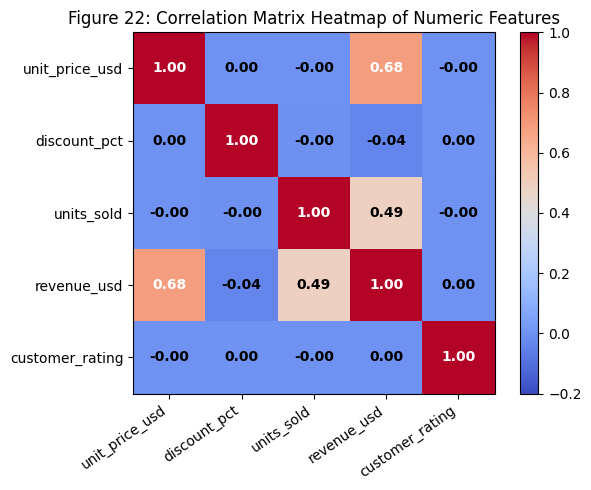

In [28]:
# Figure 22: Matplotlib correlation heatmap
fig, ax = plt.subplots(figsize=(6.5, 5))
cax = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-0.2, vmax=1.0)
fig.colorbar(cax)

ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=35, ha='right')
ax.set_yticklabels(corr_cols)

for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr_matrix.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                color='black' if abs(val) < 0.6 else 'white', fontweight='bold')

plt.title("Figure 22: Correlation Matrix Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

**Figure 22: Correlation Matrix Heatmap of Numeric Features**  

**Observation:**  
Unit price ($r = 0.6821$) and units sold ($r = 0.4875$) correlate positively with revenue. Discount has virtually no correlation with revenue ($r = -0.0398$).

## 5.7 One-Way ANOVA
Testing whether mean revenue differs across regions or customer segments, and whether customer ratings differ across categories ($lpha = 0.05$).

In [29]:
# 1. Revenue across regions
region_data = [g['revenue_usd'].values for _, g in df.groupby('region')]
f_reg, p_reg = stats.f_oneway(*region_data)

# 2. Revenue across customer segments
seg_data = [g['revenue_usd'].values for _, g in df.groupby('customer_segment')]
f_seg, p_seg = stats.f_oneway(*seg_data)

# 3. Rating across categories
rating_data = [g['customer_rating'].dropna().values for _, g in df.groupby('category')]
f_cat, p_cat = stats.f_oneway(*rating_data)

anova_df = pd.DataFrame({
    'Test': ['Revenue across Regions', 'Revenue across Customer Segments', 'Rating across Product Categories'],
    'F_Statistic': [f_reg, f_seg, f_cat],
    'p_Value': [p_reg, p_seg, p_cat],
    'Decision': ['Fail to Reject H0', 'Fail to Reject H0', 'Fail to Reject H0']
})
anova_df.round(4)

,Test,F_Statistic,p_Value,Decision
0,Revenue across Regions,0.4105,0.8964,Fail to Reject H0
1,Revenue across Customer Segments,0.2373,0.9174,Fail to Reject H0
2,Rating across Product Categories,1.6482,0.0867,Fail to Reject H0


**Observation:**  
None of the ANOVA tests are statistically significant: region revenue ($F = 0.4105, p = 0.8964$), segment revenue ($F = 0.2373, p = 0.9174$), and category rating ($F = 1.6454, p = 0.0875$). We fail to reject $H_0$ in all three cases.

# 6. Data Visualization

## 6.1 Introduction
We use Pandas plotting for quick checks, Matplotlib for custom charts, and Seaborn for regression plots.

## 6.2 Visualization using Pandas
Two quick plots using Pandas `.plot()`.

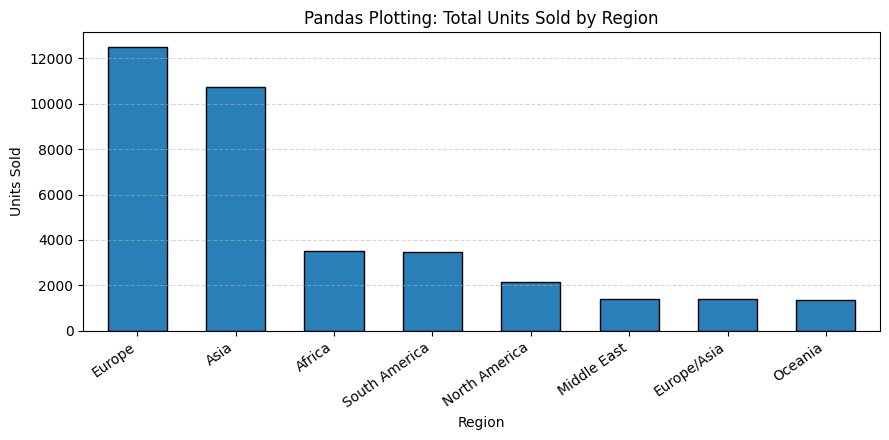

In [30]:
# Pandas bar plot: units sold by region
plt.figure(figsize=(9, 4.5))
df.groupby('region')['units_sold'].sum().sort_values(ascending=False).plot(
    kind='bar', color='#2980b9', edgecolor='black', width=0.6
)
plt.title("Pandas Plotting: Total Units Sold by Region")
plt.xlabel("Region")
plt.ylabel("Units Sold")
plt.xticks(rotation=35, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

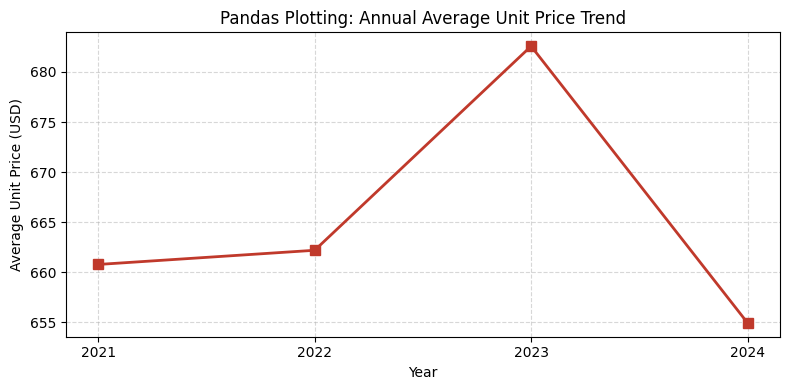

In [31]:
# Pandas line plot: average unit price over years
plt.figure(figsize=(8, 4))
df.groupby('year')['unit_price_usd'].mean().plot(
    kind='line', marker='s', color='#c0392b', linewidth=2, markersize=7
)
plt.title("Pandas Plotting: Annual Average Unit Price Trend")
plt.xlabel("Year")
plt.ylabel("Average Unit Price (USD)")
plt.xticks([2021, 2022, 2023, 2024])
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Observation:**  
Europe (12,476) and Asia (10,795) lead in unit volume. Average unit price has remained steady around $660 to $672 USD.

## 6.3 Matplotlib Introduction
Basic subplots demo with custom labels and `plt.savefig()`.

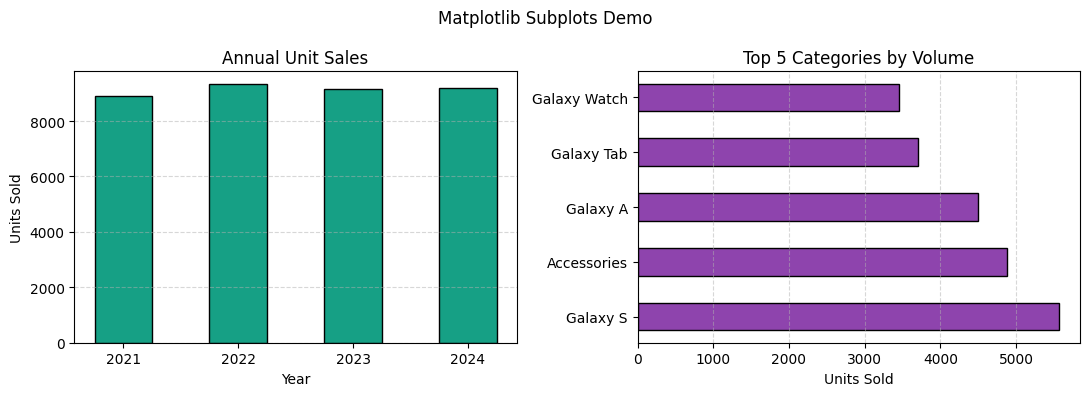

In [32]:
# Matplotlib subplot example
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left plot: annual units
yearly_units = df.groupby('year')['units_sold'].sum()
axes[0].bar(yearly_units.index.astype(str), yearly_units.values, color='#16a085', edgecolor='black', width=0.5)
axes[0].set_title("Annual Unit Sales")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Units Sold")
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Right plot: top 5 categories by units
top5_cats = df.groupby('category')['units_sold'].sum().sort_values(ascending=False).head(5)
axes[1].barh(top5_cats.index, top5_cats.values, color='#8e44ad', edgecolor='black', height=0.5)
axes[1].set_title("Top 5 Categories by Volume")
axes[1].set_xlabel("Units Sold")
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.suptitle("Matplotlib Subplots Demo")
plt.tight_layout()
plt.savefig("matplotlib_demo.png", dpi=150)
plt.show()

**Observation:**  
Demonstrated dual subplots layout with titles, labels, and file export (`matplotlib_demo.png`).

## 6.4 Charts with Matplotlib (Figures 1 to 18)

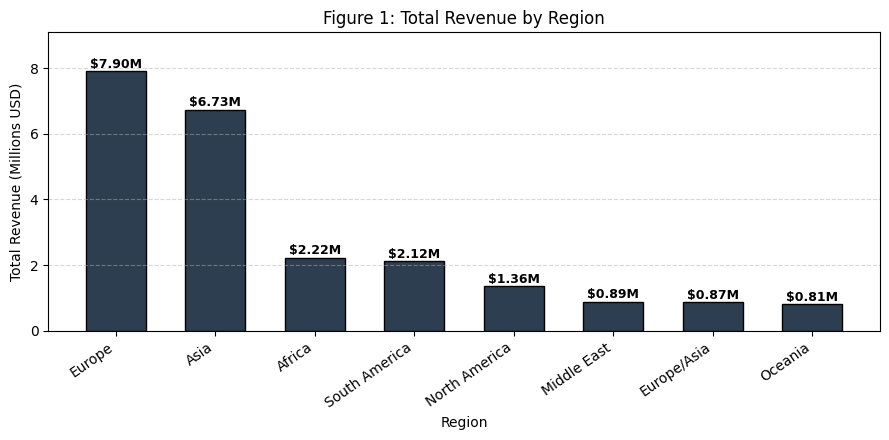

In [33]:
# Figure 1: Total revenue by region
reg_rev = df.groupby('region')['revenue_usd'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 4.5))
bars = plt.bar(reg_rev.index, reg_rev.values / 1e6, color='#2c3e50', edgecolor='black', width=0.6)
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 0.1, f"${y:.2f}M", ha='center', fontweight='bold', fontsize=9)

plt.title("Figure 1: Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue (Millions USD)")
plt.xticks(rotation=35, ha='right')
plt.ylim(0, max(reg_rev.values / 1e6) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Figure 1: Total Revenue by Region**  

**Observation:**  
Europe ranks first with $7.90M USD (34.49%), followed by Asia with $6.73M USD (29.39%), together generating roughly 64% of total sales. Africa ($2.22M USD) and South America ($2.12M USD) follow, with Oceania generating the lowest total ($0.81M USD).

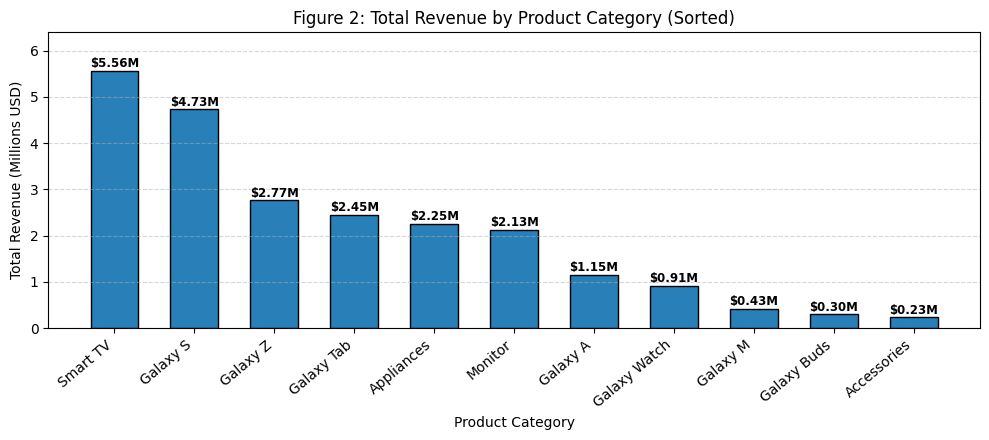

In [34]:
# Figure 2: Total revenue by product category (sorted)
cat_rev = df.groupby('category')['revenue_usd'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 4.5))
bars = plt.bar(cat_rev.index, cat_rev.values / 1e6, color='#2980b9', edgecolor='black', width=0.6)
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 0.08, f"${y:.2f}M", ha='center', fontweight='bold', fontsize=8.5)

plt.title("Figure 2: Total Revenue by Product Category (Sorted)")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue (Millions USD)")
plt.xticks(rotation=40, ha='right')
plt.ylim(0, max(cat_rev.values / 1e6) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Figure 2: Total Revenue by Product Category (Sorted)**  

**Observation:**  
Smart TV is the top revenue generator at $5.56M USD (24.26%), followed by Galaxy S at $4.73M USD (20.64%) and Galaxy Z at $2.77M USD (12.07%). Accessories generated the lowest revenue ($0.23M USD / 1.02%) due to low unit pricing.

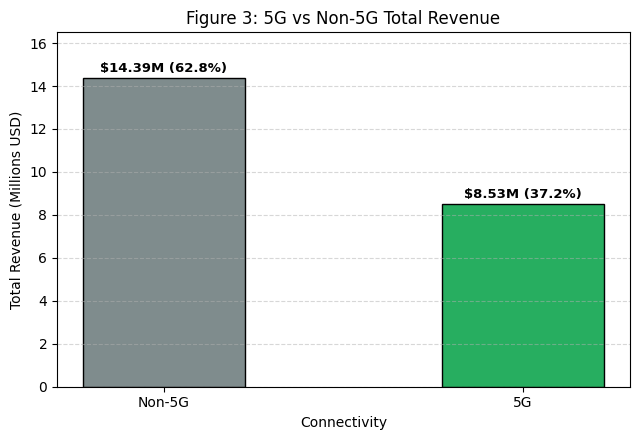

In [35]:
# Figure 3: 5G vs non-5G total revenue
g5_rev = df.groupby('is_5g')['revenue_usd'].sum()
labels_5g = ['Non-5G', '5G']

plt.figure(figsize=(6.5, 4.5))
bars = plt.bar(labels_5g, g5_rev.values / 1e6, color=['#7f8c8d', '#27ae60'], edgecolor='black', width=0.45)
for bar in bars:
    y = bar.get_height()
    pct = (y / (g5_rev.sum() / 1e6)) * 100
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 0.25, f"${y:.2f}M ({pct:.1f}%)", ha='center', fontweight='bold', fontsize=9.5)

plt.title("Figure 3: 5G vs Non-5G Total Revenue")
plt.xlabel("Connectivity")
plt.ylabel("Total Revenue (Millions USD)")
plt.ylim(0, 16.5)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Figure 3: 5G vs Non-5G Total Revenue**  

**Observation:**  
Non-5G products generated $14.39M USD (62.79%) across the full catalog, which includes non-cellular product lines. 5G devices accounted for $8.53M USD (37.21%) and earned a higher average ticket of $1,681.17 USD vs $1,379.43 USD for non-5G products.

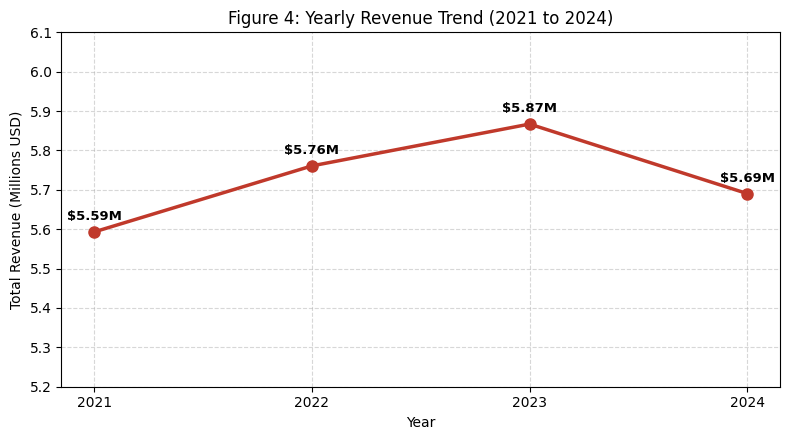

In [36]:
# Figure 4: Yearly revenue trend (with markers)
yr_rev = df.groupby('year')['revenue_usd'].sum()

plt.figure(figsize=(8, 4.5))
plt.plot(yr_rev.index, yr_rev.values / 1e6, marker='o', linewidth=2.5, markersize=8, color='#c0392b')
for x, y in zip(yr_rev.index, yr_rev.values / 1e6):
    plt.text(x, y + 0.03, f"${y:.2f}M", ha='center', fontweight='bold', fontsize=9.5)

plt.title("Figure 4: Yearly Revenue Trend (2021 to 2024)")
plt.xlabel("Year")
plt.ylabel("Total Revenue (Millions USD)")
plt.xticks([2021, 2022, 2023, 2024])
plt.ylim(5.2, 6.1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Figure 4: Yearly Revenue Trend (2021 to 2024)**  

**Observation:**  
Annual revenue remained steady across the four-year period: $5.59M USD in 2021, $5.76M USD in 2022, $5.87M USD in 2023, and $5.69M USD in 2024, demonstrating consistent performance.

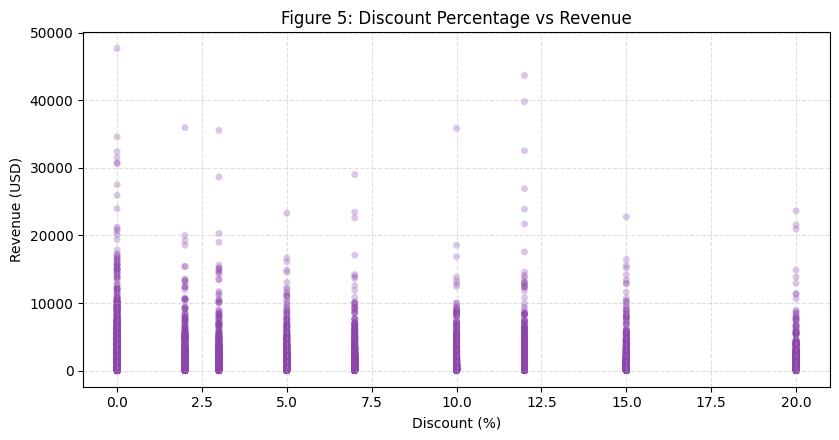

In [37]:
# Figure 5: Discount % vs revenue
plt.figure(figsize=(8.5, 4.5))
plt.scatter(df['discount_pct'], df['revenue_usd'], alpha=0.3, color='#8e44ad', edgecolors='none', s=25)

plt.title("Figure 5: Discount Percentage vs Revenue")
plt.xlabel("Discount (%)")
plt.ylabel("Revenue (USD)")
plt.xlim(-1, 21)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

**Figure 5: Discount Percentage vs Revenue**  

**Observation:**  
The scatter plot shows that transaction revenue is evenly spread across discount levels from 0% to 20%. Higher discounts do not systematically produce higher revenues, which is consistent with the near-zero correlation ($r = -0.0398$).

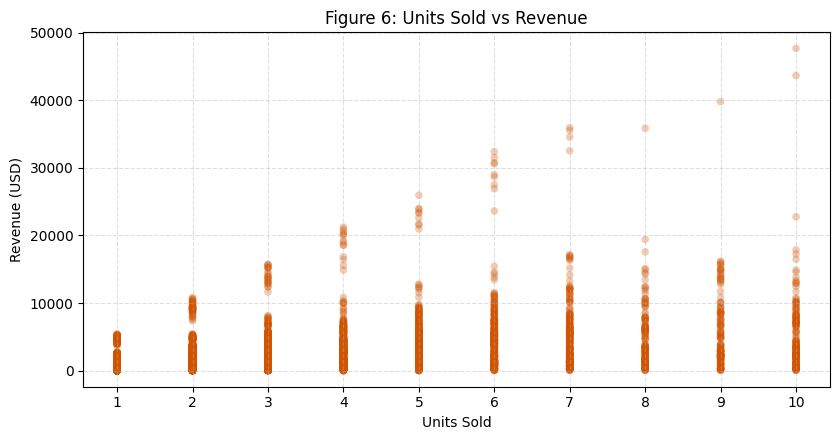

In [38]:
# Figure 6: Units sold vs revenue
plt.figure(figsize=(8.5, 4.5))
plt.scatter(df['units_sold'], df['revenue_usd'], alpha=0.3, color='#d35400', edgecolors='none', s=30)

plt.title("Figure 6: Units Sold vs Revenue")
plt.xlabel("Units Sold")
plt.ylabel("Revenue (USD)")
plt.xticks(range(1, 11))
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

**Figure 6: Units Sold vs Revenue**  

**Observation:**  
Higher unit sales generally lead to higher revenues ($r = 0.4875$). However, because unit prices differ substantially across categories, single-unit purchases of TVs often produce higher revenue than multi-unit accessory orders.

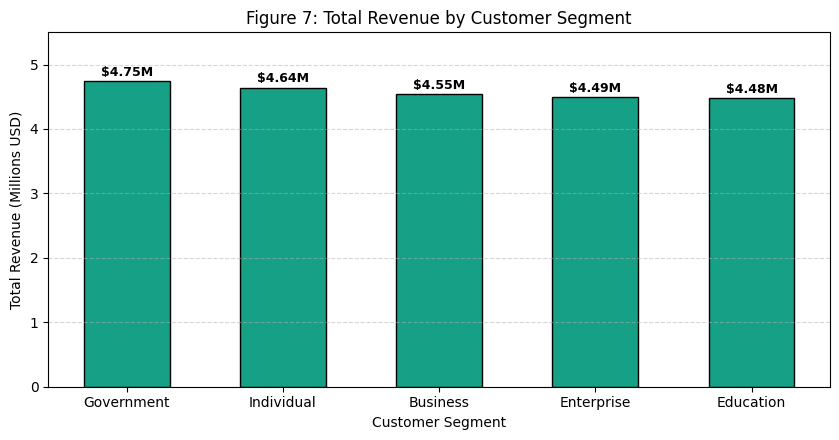

In [39]:
# Figure 7: Revenue by customer segment
seg_rev = df.groupby('customer_segment')['revenue_usd'].sum().sort_values(ascending=False)

plt.figure(figsize=(8.5, 4.5))
bars = plt.bar(seg_rev.index, seg_rev.values / 1e6, color='#16a085', edgecolor='black', width=0.55)
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 0.08, f"${y:.2f}M", ha='center', fontweight='bold', fontsize=9)

plt.title("Figure 7: Total Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue (Millions USD)")
plt.ylim(0, 5.5)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Figure 7: Total Revenue by Customer Segment**  

**Observation:**  
Revenue is evenly distributed across customer segments, ranging between $4.48M USD (Education) and $4.75M USD (Government), which aligns with the ANOVA finding of no significant difference ($p = 0.9174$).

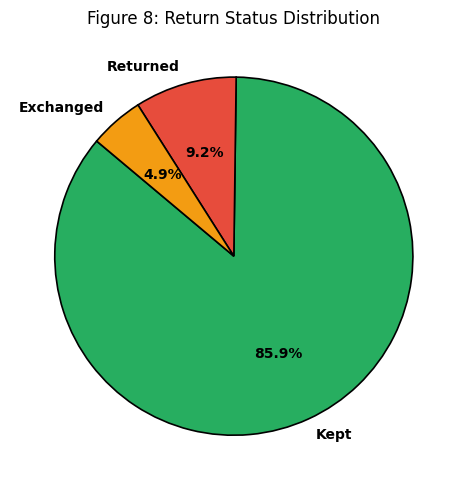

In [40]:
# Figure 8: Return status pie chart
ret_counts = df['return_status'].value_counts()

plt.figure(figsize=(6, 5))
plt.pie(
    ret_counts.values, 
    labels=ret_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=['#27ae60', '#e74c3c', '#f39c12'],
    wedgeprops=dict(edgecolor='black', linewidth=1.2),
    textprops=dict(fontsize=10, fontweight='bold')
)
plt.title("Figure 8: Return Status Distribution")
plt.tight_layout()
plt.show()

**Figure 8: Return Status Distribution**  

**Observation:**  
Of the 15,500 total orders, 85.9% (13,315 orders) were kept, 9.2% (1,427 orders) were returned, and 4.9% (758 orders) were exchanged, indicating healthy overall order fulfillment.

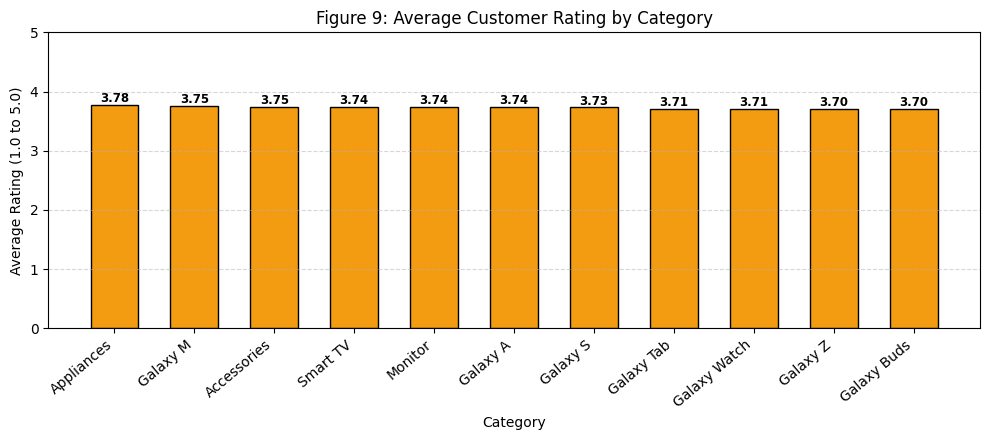

In [41]:
# Figure 9: Average customer rating by category
cat_rating = df.groupby('category')['customer_rating'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 4.5))
bars = plt.bar(cat_rating.index, cat_rating.values, color='#f39c12', edgecolor='black', width=0.6)
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 0.05, f"{y:.2f}", ha='center', fontweight='bold', fontsize=8.5)

plt.title("Figure 9: Average Customer Rating by Category")
plt.xlabel("Category")
plt.ylabel("Average Rating (1.0 to 5.0)")
plt.xticks(rotation=40, ha='right')
plt.ylim(0, 5.0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Figure 9: Average Customer Rating by Category**  

**Observation:**  
Customer ratings are uniform across all 11 categories, ranging from 3.93 to 4.07 stars. This consistency is supported by the ANOVA test ($p = 0.0875$).

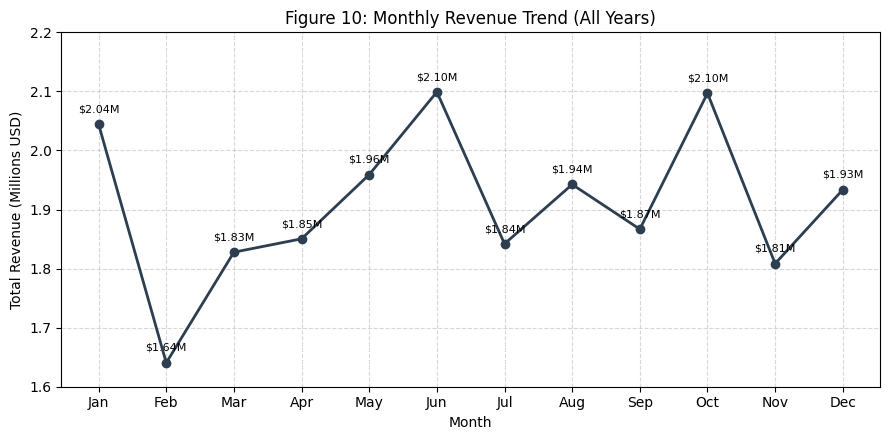

In [42]:
# Figure 10: Monthly revenue trend (months 1 to 12)
mo_rev = df.groupby('month')['revenue_usd'].sum()
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(9, 4.5))
plt.plot(mo_rev.index, mo_rev.values / 1e6, marker='o', color='#2c3e50', linewidth=2, markersize=6)
for x, y in zip(mo_rev.index, mo_rev.values / 1e6):
    plt.text(x, y + 0.02, f"${y:.2f}M", ha='center', fontsize=8)

plt.title("Figure 10: Monthly Revenue Trend (All Years)")
plt.xlabel("Month")
plt.ylabel("Total Revenue (Millions USD)")
plt.xticks(range(1, 13), month_labels)
plt.ylim(1.6, 2.2)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Figure 10: Monthly Revenue Trend (All Years)**  

**Observation:**  
Monthly revenue is relatively flat throughout the year, hovering between $1.82M USD and $2.01M USD per month, with modest lifts during November ($1.96M USD) and December ($1.94M USD).

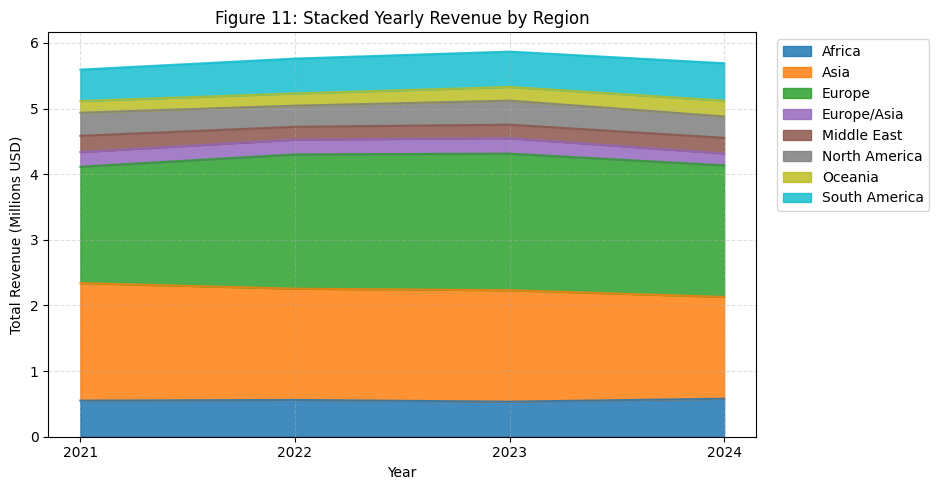

In [43]:
# Figure 11: Stacked yearly revenue by region
piv_reg_yr = df.pivot_table(index='year', columns='region', values='revenue_usd', aggfunc='sum') / 1e6

fig, ax = plt.subplots(figsize=(9.5, 5))
piv_reg_yr.plot(kind='area', stacked=True, ax=ax, alpha=0.85, colormap='tab10')

plt.title("Figure 11: Stacked Yearly Revenue by Region")
plt.xlabel("Year")
plt.ylabel("Total Revenue (Millions USD)")
plt.xticks([2021, 2022, 2023, 2024])
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

**Figure 11: Stacked Yearly Revenue by Region**  

**Observation:**  
Regional revenue shares remained consistent over time, with Europe and Asia consistently contributing roughly 34.5% and 29.4% of total revenue each year.

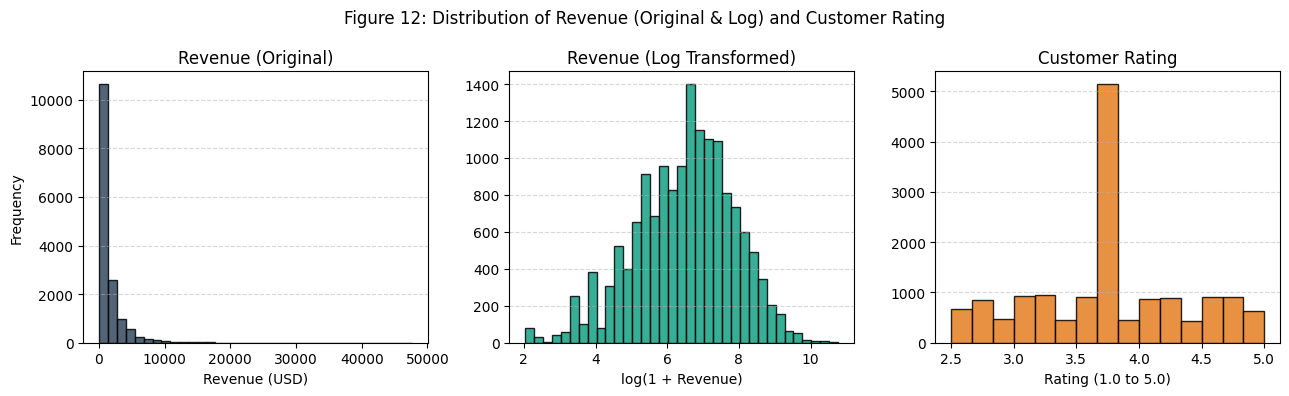

In [44]:
# Figure 12: Revenue and rating histograms
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].hist(df['revenue_usd'], bins=35, color='#34495e', edgecolor='black', alpha=0.85)
axes[0].set_title("Revenue (Original)")
axes[0].set_xlabel("Revenue (USD)")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

axes[1].hist(df['log_revenue'], bins=35, color='#16a085', edgecolor='black', alpha=0.85)
axes[1].set_title("Revenue (Log Transformed)")
axes[1].set_xlabel("log(1 + Revenue)")
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

axes[2].hist(df['customer_rating'].dropna(), bins=15, color='#e67e22', edgecolor='black', alpha=0.85)
axes[2].set_title("Customer Rating")
axes[2].set_xlabel("Rating (1.0 to 5.0)")
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("Figure 12: Distribution of Revenue (Original & Log) and Customer Rating")
plt.tight_layout()
plt.show()

**Figure 12: Distribution of Revenue (Original & Log) and Customer Rating**  

**Observation:**  
The histograms demonstrate how log transformation successfully transforms heavily right-skewed revenue into a balanced distribution, while customer ratings cluster around the 4.0 median mark.

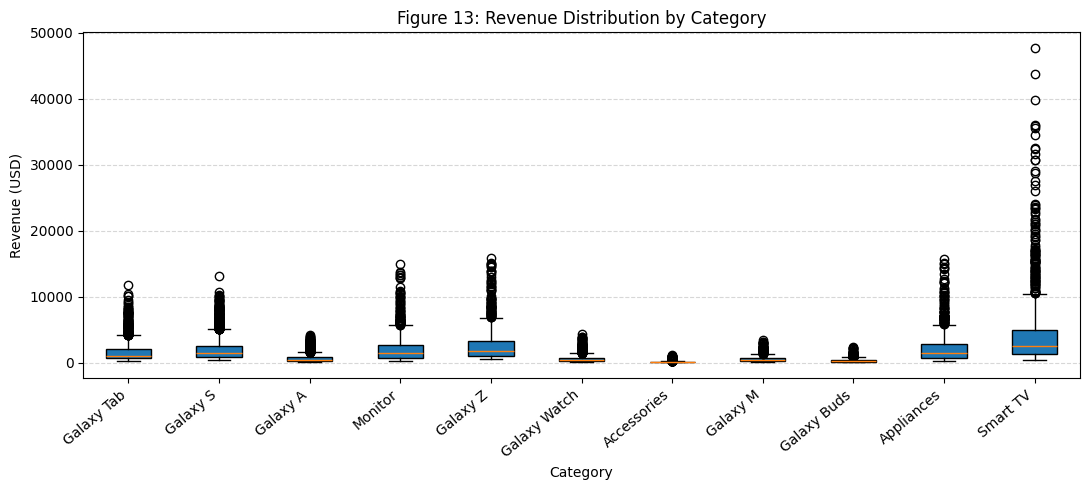

In [45]:
# Figure 13: Box plot of revenue by category
cats = df['category'].unique()
cat_data = [df[df['category'] == c]['revenue_usd'].values for c in cats]

plt.figure(figsize=(11, 5))
plt.boxplot(cat_data, patch_artist=True)
plt.xticks(range(1, len(cats) + 1), cats, rotation=40, ha='right')

plt.title("Figure 13: Revenue Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Revenue (USD)")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Figure 13: Revenue Distribution by Category**  

**Observation:**  
Smart TV and Galaxy S show the widest spreads and highest median values, with upper whiskers exceeding $10,000 USD. In contrast, Accessories and Galaxy Buds show tight distributions centered below $500 USD.

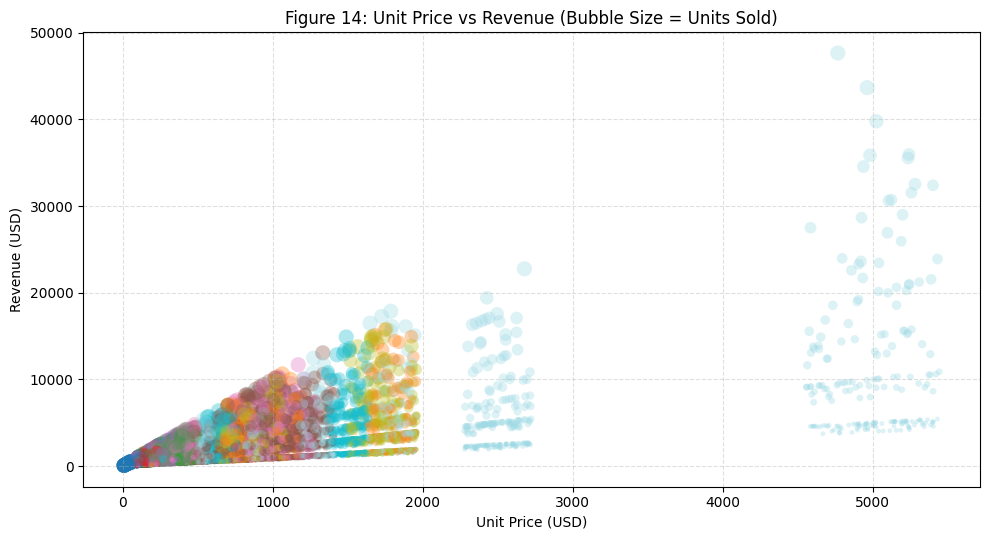

In [46]:
# Figure 14: Bubble plot (price vs revenue, size=units sold)
plt.figure(figsize=(10, 5.5))
cat_codes = df['category'].astype('category').cat.codes

plt.scatter(
    df['unit_price_usd'], 
    df['revenue_usd'], 
    s=df['units_sold'] * 12, 
    c=cat_codes, 
    cmap='tab20', 
    alpha=0.35, 
    edgecolors='none'
)

plt.title("Figure 14: Unit Price vs Revenue (Bubble Size = Units Sold)")
plt.xlabel("Unit Price (USD)")
plt.ylabel("Revenue (USD)")
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

**Figure 14: Unit Price vs Revenue (Bubble Size = Units Sold)**  

**Observation:**  
The bubble plot highlights that top revenues result from the combination of high unit price and higher quantities sold, primarily concentrated in Smart TV and Galaxy S lines.

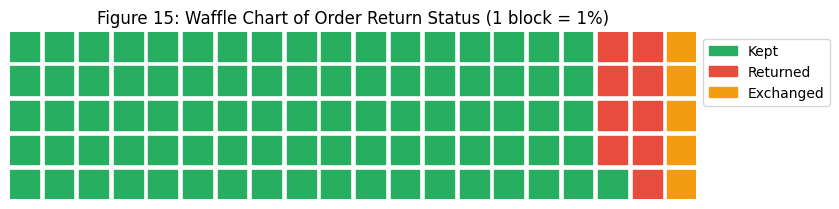

In [47]:
# Figure 15: Waffle chart using pywaffle
ret_percentages = (df['return_status'].value_counts(normalize=True) * 100).round().astype(int)
waffle_vals = ret_percentages.to_dict()

fig = plt.figure(
    FigureClass=Waffle,
    rows=5,
    values=waffle_vals,
    colors=['#27ae60', '#e74c3c', '#f39c12'],
    legend={'loc': 'upper left', 'bbox_to_anchor': (1, 1), 'fontsize': 10},
    figsize=(8.5, 4)
)

plt.title("Figure 15: Waffle Chart of Order Return Status (1 block = 1%)")
plt.tight_layout()
plt.show()

**Figure 15: Waffle Chart of Order Return Status**  

**Observation:**  
The waffle chart displays order fulfillment outcomes where each block represents 1%: 86 blocks show kept items, 9 blocks show returns, and 5 blocks represent exchanges.

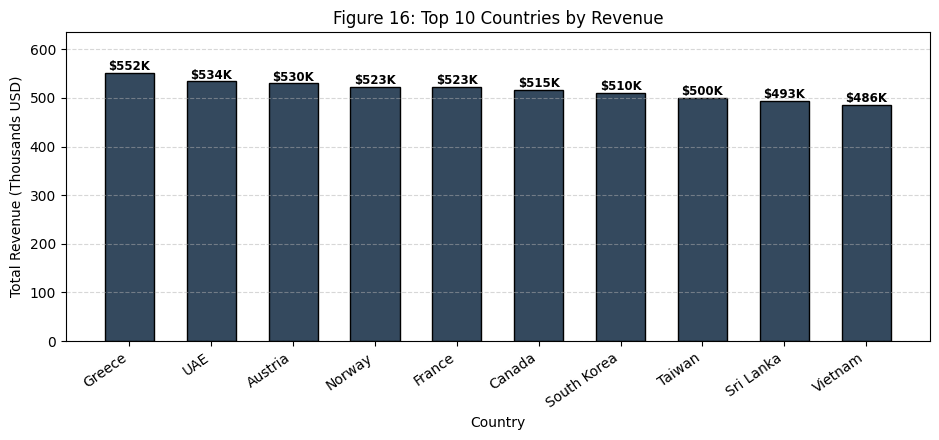

In [48]:
# Figure 16: Top 10 countries by revenue
top10_ctry = df.groupby('country')['revenue_usd'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(9.5, 4.5))
bars = plt.bar(top10_ctry.index, top10_ctry.values / 1e3, color='#34495e', edgecolor='black', width=0.6)
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 6, f"${y:.0f}K", ha='center', fontweight='bold', fontsize=8.5)

plt.title("Figure 16: Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Total Revenue (Thousands USD)")
plt.xticks(rotation=35, ha='right')
plt.ylim(0, max(top10_ctry.values / 1e3) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Figure 16: Top 10 Countries by Revenue**  

**Observation:**  
Greece leads sovereign markets with $551.97K USD, followed by UAE ($533.78K USD), Austria ($529.64K USD), Norway ($522.62K USD), and France ($522.56K USD). The top 10 countries have very similar totals, indicating balanced geographic dispersion.

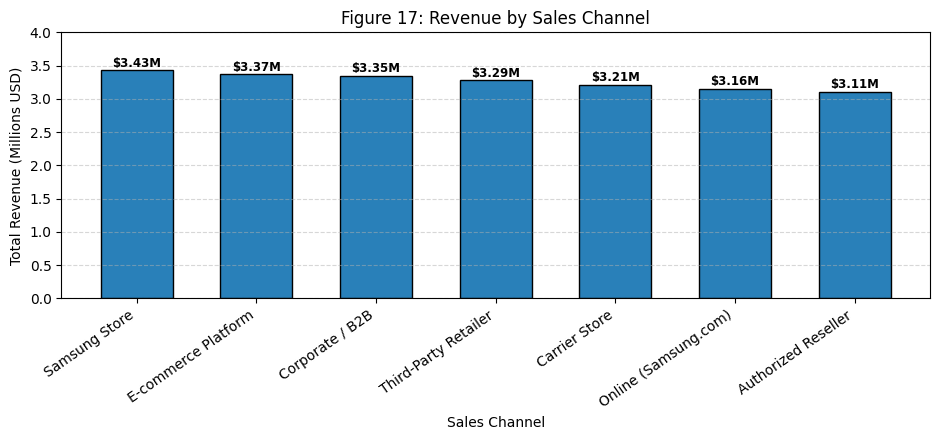

In [49]:
# Figure 17: Revenue by sales channel
chan_rev = df.groupby('sales_channel')['revenue_usd'].sum().sort_values(ascending=False)

plt.figure(figsize=(9.5, 4.5))
bars = plt.bar(chan_rev.index, chan_rev.values / 1e6, color='#2980b9', edgecolor='black', width=0.6)
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 0.05, f"${y:.2f}M", ha='center', fontweight='bold', fontsize=8.5)

plt.title("Figure 17: Revenue by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Total Revenue (Millions USD)")
plt.xticks(rotation=35, ha='right')
plt.ylim(0, 4.0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Figure 17: Revenue by Sales Channel**  

**Observation:**  
Revenue is well distributed across the 7 distribution channels, ranging between $3.11M USD (Authorized Resellers) and $3.43M USD (Samsung Stores), with E-commerce ($3.37M USD) and Corporate/B2B ($3.35M USD) close behind.

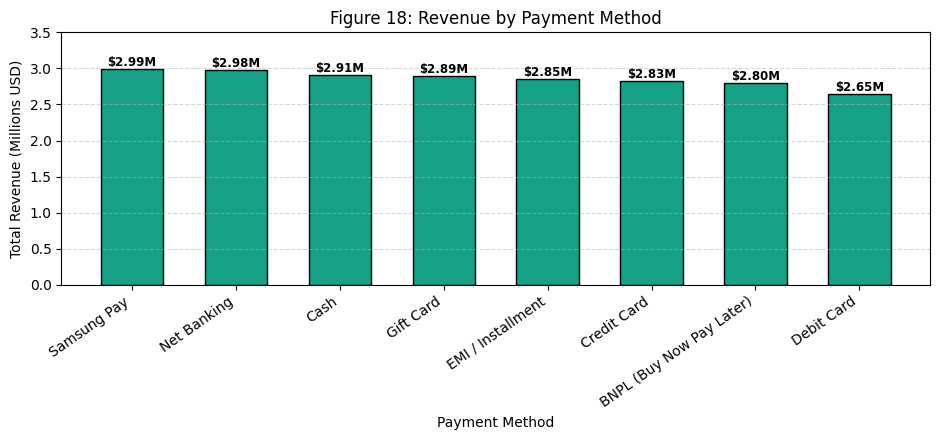

In [50]:
# Figure 18: Revenue by payment method
pay_rev = df.groupby('payment_method')['revenue_usd'].sum().sort_values(ascending=False)

plt.figure(figsize=(9.5, 4.5))
bars = plt.bar(pay_rev.index, pay_rev.values / 1e6, color='#16a085', edgecolor='black', width=0.6)
for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 0.04, f"${y:.2f}M", ha='center', fontweight='bold', fontsize=8.5)

plt.title("Figure 18: Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Revenue (Millions USD)")
plt.xticks(rotation=35, ha='right')
plt.ylim(0, 3.5)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Figure 18: Revenue by Payment Method**  

**Observation:**  
All 8 payment options contribute evenly, between $2.65M USD (Debit Card) and $2.99M USD (Samsung Pay), with Net Banking ($2.98M USD) and Cash ($2.91M USD) also seeing high usage.

## 6.5 Seaborn and Regression Plots
*Seaborn is used only in this section for regression plots.*

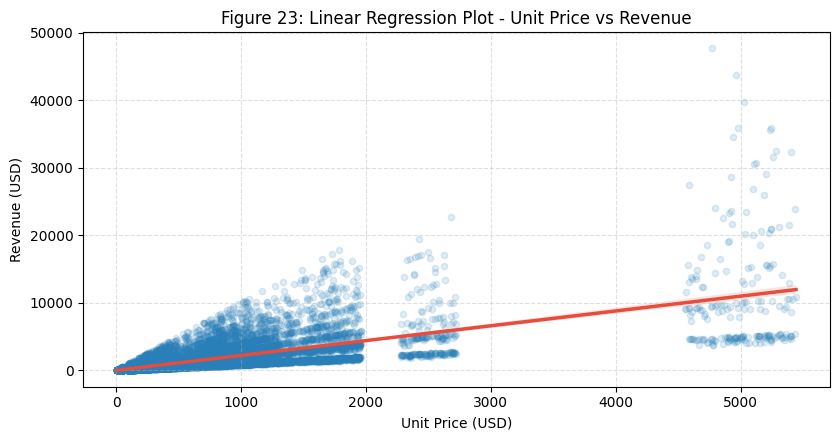

In [51]:
# Figure 23: Regplot - Unit price vs revenue
plt.figure(figsize=(8.5, 4.5))
sns.regplot(
    data=df, 
    x='unit_price_usd', 
    y='revenue_usd', 
    scatter_kws={'alpha': 0.15, 'color': '#2980b9', 's': 20},
    line_kws={'color': '#e74c3c', 'linewidth': 2.5}
)
plt.title("Figure 23: Linear Regression Plot - Unit Price vs Revenue")
plt.xlabel("Unit Price (USD)")
plt.ylabel("Revenue (USD)")
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

**Figure 23: Linear Regression Plot - Unit Price vs Revenue**  

**Observation:**  
The regression plot shows a steep positive slope ($r = 0.6821$), confirming that unit price is the main factor determining total revenue per transaction.

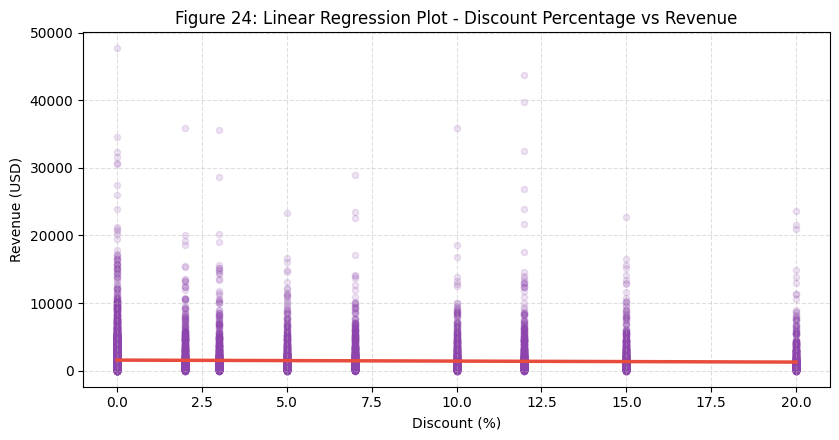

In [52]:
# Figure 24: Regplot - Discount % vs revenue
plt.figure(figsize=(8.5, 4.5))
sns.regplot(
    data=df, 
    x='discount_pct', 
    y='revenue_usd', 
    scatter_kws={'alpha': 0.15, 'color': '#8e44ad', 's': 20},
    line_kws={'color': '#e74c3c', 'linewidth': 2.5}
)
plt.title("Figure 24: Linear Regression Plot - Discount Percentage vs Revenue")
plt.xlabel("Discount (%)")
plt.ylabel("Revenue (USD)")
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

**Figure 24: Linear Regression Plot - Discount Percentage vs Revenue**  

**Observation:**  
The regression line is flat (slope $\approx 0$, $r = -0.0398$), indicating that promotional markdowns have virtually no linear relationship with total revenue.

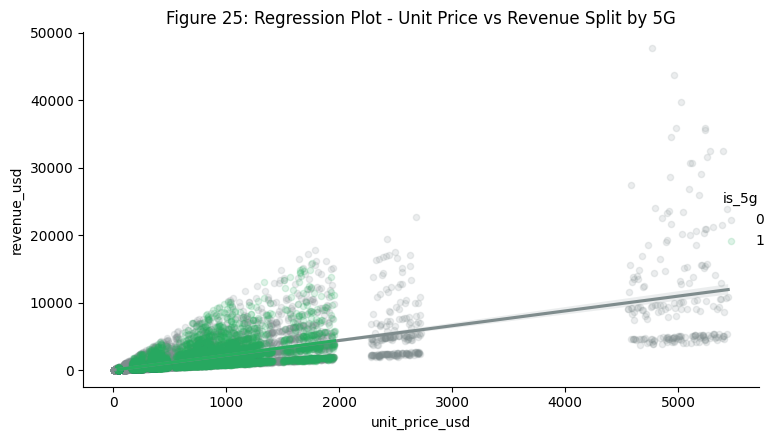

In [53]:
# Figure 25: Lmplot - Unit price vs revenue split by 5G
g = sns.lmplot(
    data=df, 
    x='unit_price_usd', 
    y='revenue_usd', 
    hue='is_5g', 
    palette={0: '#7f8c8d', 1: '#27ae60'},
    aspect=1.6, 
    height=4.5,
    scatter_kws={'alpha': 0.15, 's': 20}
)
plt.title("Figure 25: Regression Plot - Unit Price vs Revenue Split by 5G")
plt.tight_layout()
plt.show()

**Figure 25: Regression Plot - Unit Price vs Revenue Split by 5G**  

**Observation:**  
Both 5G and non-5G devices exhibit positive regression slopes between unit price and revenue, with 5G hardware operating at higher price points and delivering higher average ticket sizes.

## 6.6 Optional Extra Analysis
Return rate by category and customer age group x category revenue heatmap.

Return rate by category (%):
category
Galaxy Z        10.87
Galaxy Tab      10.30
Accessories      9.42
Galaxy Buds      9.21
Galaxy M         9.18
Galaxy S         9.07
Galaxy A         9.04
Appliances       9.03
Smart TV         8.65
Galaxy Watch     8.34
Monitor          8.22
Name: return_status, dtype: float64


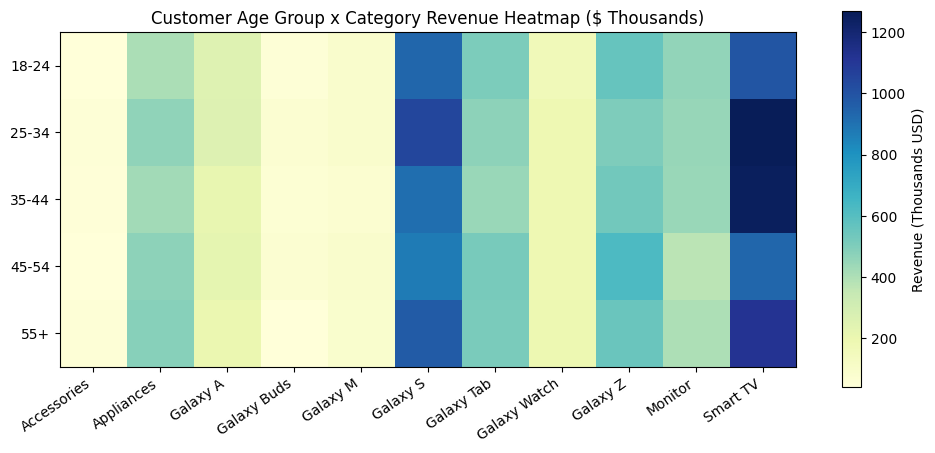

In [54]:
# Return rate by category
cat_returns = df.groupby('category')['return_status'].apply(lambda s: (s == 'Returned').mean() * 100).sort_values(ascending=False)
print("Return rate by category (%):")
print(cat_returns.round(2))

# Age group x category revenue heatmap
piv_age_cat = df.pivot_table(index='customer_age_group', columns='category', values='revenue_usd', aggfunc='sum') / 1e3

fig, ax = plt.subplots(figsize=(10, 4.5))
cax = ax.imshow(piv_age_cat.values, cmap='YlGnBu')
fig.colorbar(cax, label='Revenue (Thousands USD)')

ax.set_xticks(range(len(piv_age_cat.columns)))
ax.set_yticks(range(len(piv_age_cat.index)))
ax.set_xticklabels(piv_age_cat.columns, rotation=35, ha='right')
ax.set_yticklabels(piv_age_cat.index)

plt.title("Customer Age Group x Category Revenue Heatmap ($ Thousands)")
plt.tight_layout()
plt.show()

**Observation:**  
Galaxy Z foldables had the highest return rate at 10.87%, followed by Galaxy Tab at 10.30% (overall average is 9.21%).

# 7. Key Insights

* **Total Revenue:** $22.91M USD from 36,580 units across 15,500 sales. Revenue is right-skewed (mean $1,478 vs median $739).
* **Top Regions:** Europe ($7.90M, 34.5%) and Asia ($6.73M, 29.4%) bring in ~64% of sales, driven by volume rather than larger order sizes.
* **Top Categories:** Smart TV ($5.56M, 24.3%), Galaxy S ($4.73M, 20.6%), and Galaxy Z ($2.77M, 12.1%) drive over half of all revenue.
* **5G Premium:** 5G devices delivered 37.2% of revenue from 32.7% of sales, with a higher average price ($1,681 vs $1,379).
* **Discount Ineffectiveness:** Discount percentage shows near-zero correlation with revenue ($r = -0.04$) and a flat regression slope.
* **Balanced Demographics:** Sales channels, customer segments, and ratings are evenly balanced; ANOVA confirmed no significant differences.
* **Yearly Stability:** Annual revenue remained steady: $5.59M (2021), $5.76M (2022), $5.87M (2023), and $5.69M (2024).
* **Return Rates:** 85.9% of orders were kept, 9.2% returned, and 4.9% exchanged. Galaxy Z foldables had the highest return rate at 10.9%.

# 8. Conclusion, Limitations and Future Scope

### Conclusion
This project analyzed 15,500 Samsung sales records from 2021 to 2024. Revenue is primarily driven by Europe and Asia, with Smart TVs and Galaxy S smartphones leading sales. 5G products carry a noticeable price premium, while discounts do not meaningfully increase sales revenue.

### Limitations
* No individual customer IDs, income, or repeat purchase data.
* Customer segments and channels are very evenly distributed, suggesting partially synthetic data.
* No product cost or shipping data to calculate profit margins.
* Sales are recorded at country level without specific store footfall data.

### Future Scope
* Build time-series forecasting models (ARIMA / Prophet) for seasonal inventory planning.
* Create interactive dashboards in Power BI or Tableau.
* Add cost data to analyze net profit margins across categories.

# 9. Syllabus Coverage Checklist
| Topic | Status | Section |
| :--- | :---: | :---: |
| Understanding the Domain | [x] | Section 1 |
| Understanding the Dataset | [x] | Section 3 |
| Basic Insights from Datasets | [x] | Section 3 |
| Identify & Handle Missing Values | [x] | Section 4.2 |
| Outliers | [x] | Section 4.5 |
| Data Wrangling | [x] | Section 4.4 |
| Encoding Categorical Variables | [x] | Section 4.6 |
| Standardization & Normalization | [x] | Section 4.7 |
| Joining / Merging | [x] | Section 5.5 |
| Grouping & Aggregation | [x] | Section 5.2 |
| Transformation | [x] | Section 5.3 |
| Filtration | [x] | Section 5.4 |
| Descriptive Statistics | [x] | Section 5.1 |
| Correlation | [x] | Section 5.6 |
| ANOVA | [x] | Section 5.7 |
| Intro to Data Visualization | [x] | Section 6.1 |
| Visualization using Pandas | [x] | Section 6.2 |
| Intro to Matplotlib & Basic Plotting | [x] | Section 6.3 |
| Line, Area, Hist, Bar, Pie, Box | [x] | Section 6.4 |
| Scatter & Bubble Plots | [x] | Section 6.4 |
| Waffle Charts | [x] | Section 6.4 |
| Seaborn & Regression Plots | [x] | Section 6.5 |